# A ReAct agent revises its plan after a rejected truss edit

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cmudrc/design-research-workshop/blob/workshop-three-agent-demos/notebooks/planar_truss_react.ipynb)

Watch a tool-using agent inspect a planar-truss seed, add members through the grammar, and finish with the geometry it actually observed.

Run each numbered section in order. A CPU runtime is enough. The workshop backend uses deterministic rules and runs without an API key.

## 1. Set up
Run the install cell once in Colab. If you installed the workshop package locally, start in the next section.

In [ ]:
# @title Install the workshop package { display-mode: "form" }
%pip -q install "design-research-workshop @ git+https://github.com/cmudrc/design-research-workshop.git@workshop-three-agent-demos"

## 2. Inspect the starting geometry

The seed has two supports and a loaded joint. The goal is to add the three sides of a triangle. Predict which tool the agent should call first, and what information it needs from that call.

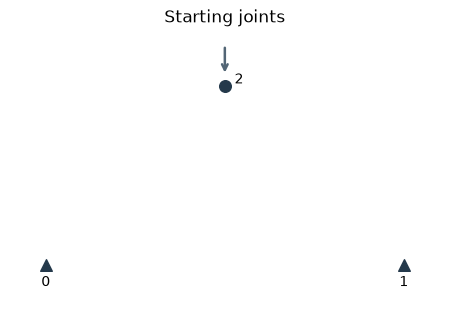

In [1]:
# @title Set the geometry and target { display-mode: "form" }
import json
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from design_research_workshop import workshop_client
from design_research_workshop.truss import TrussDesign, truss_agent

target = [[0, 1], [0, 2], [1, 2]]
seed = TrussDesign().state

def plot_design(ax, state, title):
    joints = {joint.joint_id: joint for joint in state.joints}
    for member in state.members:
        left, right = joints[member.start_joint_id], joints[member.end_joint_id]
        ax.plot([left.x, right.x], [left.y, right.y], color="#9C2035", lw=3)
    for joint in joints.values():
        marker = "o" if joint.support_type == "free" else "^"
        ax.scatter(joint.x, joint.y, s=70, marker=marker, color="#24394B", zorder=3)
        offset = (7, 2) if joint.support_type == "free" else (0, -15)
        ax.annotate(str(joint.joint_id), (joint.x, joint.y), xytext=offset,
                    ha="left" if joint.support_type == "free" else "center",
                    textcoords="offset points")
    loaded_joint = joints[state.load_joint_id]
    ax.annotate("", (loaded_joint.x, loaded_joint.y + 0.3),
                (loaded_joint.x, loaded_joint.y + 1.15),
                arrowprops={"arrowstyle": "->", "color": "#526575", "lw": 1.8})
    ax.set(xlim=(-1, state.span + 1), ylim=(-1, state.max_height + 1.55),
           title=title, aspect="equal")
    ax.axis("off")

def run_case(try_first):
    design = TrussDesign()
    with workshop_client() as client, truss_agent(client, design) as agent:
        task = json.dumps({"target_members": target, "try_first": try_first})
        outcome = agent.run(task, request_id="workshop-planar-truss")
    return design.state, outcome

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
plot_design(ax, seed, "Starting joints")
plt.show()

## 3. Case A — Build from legal moves

Observe what the inspect tool returns, then watch the agent update the state one member at a time.

In [2]:
clean_state, clean_result = run_case(try_first=None)
for tool in clean_result.tool_results:
    print(tool.tool_name, tool.result)
print("Reported design:", clean_result.final_output)

truss.inspect {'members': [], 'legal_additions': [[0, 1], [0, 2], [1, 2]]}
truss.add_member {'members': [[0, 1]], 'legal_additions': [[0, 2], [1, 2]], 'status': 'Added member 0–1.'}
truss.add_member {'members': [[0, 1], [0, 2]], 'legal_additions': [[1, 2]], 'status': 'Added member 0–2.'}
truss.add_member {'members': [[0, 1], [0, 2], [1, 2]], 'legal_additions': [], 'status': 'Added member 1–2.'}
Reported design: {'members': [[0, 1], [0, 2], [1, 2]], 'missing': []}


## 4. Case B — Recover from a rejected move

Ask the agent to check joint pair 0–99 first. The tool reports the rejection, the current geometry, and the moves that remain available. Read the action and observation at that step and the action immediately after it.

In [3]:
candidate_first = [0, 99]  # Try [0, 2] for a valid first member.
recovered_state, recovered_result = run_case(try_first=candidate_first)
rows = ["| Step | Action | Tool observation |", "| ---: | --- | --- |"]
for step, tool in enumerate(recovered_result.tool_results, 1):
    observation = tool.result
    status = observation.get("status", "Inspected the starting design.")
    rows.append(f"| {step} | `{tool.tool_name}` | {status} Members now {observation['members']}. |")
display(Markdown("\n".join(rows)))
print("Reported design:", recovered_result.final_output)

| Step | Action | Tool observation |
| ---: | --- | --- |
| 1 | `truss.inspect` | Inspected the starting design. Members now []. |
| 2 | `truss.add_member` | Rejected 0–99. That member is outside the legal moves. Members now []. |
| 3 | `truss.add_member` | Added member 0–1. Members now [[0, 1]]. |
| 4 | `truss.add_member` | Added member 0–2. Members now [[0, 1], [0, 2]]. |
| 5 | `truss.add_member` | Added member 1–2. Members now [[0, 1], [0, 2], [1, 2]]. |

Reported design: {'members': [[0, 1], [0, 2], [1, 2]], 'missing': []}


## 5. Compare the resulting designs

Compare the initial geometry with the two final designs. Then compare the path lengths using the action traces above.

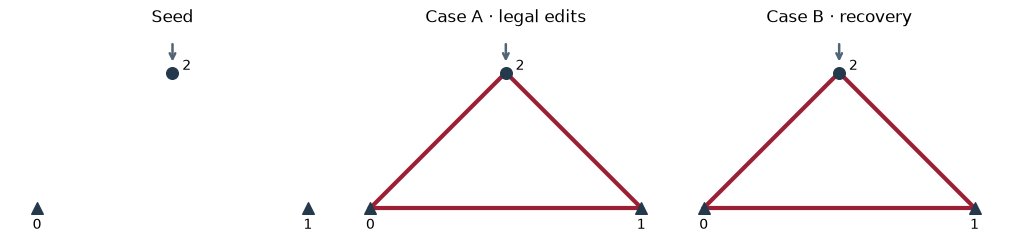

In [4]:
fig, plots = plt.subplots(1, 3, figsize=(10, 3.1), layout="constrained")
for ax, state, label in zip(
    plots, (seed, clean_state, recovered_state),
    ("Seed", "Case A · legal edits", "Case B · recovery"), strict=True,
):
    plot_design(ax, state, label)
plt.show()

## Discuss

When did the observation change the agent’s next action? Rerun Case B with a valid first member, or remove one edge from the target and repeat both cases. Compare the final geometry and the sequence of actions. The notebook uses the [packaged planar-truss grammar](https://cmudrc.github.io/design-research/tutorials/problems_truss_grammar.html).